forcasting and targets

In [39]:

%pip install statsmodels

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

root = Path(".").resolve()
processed = root / "data" / "processed"
raw = root / "data" / "raw"
out_ch = root / "outputs" / "charts"
out_tb = root / "outputs" / "tables"
out_ch.mkdir(parents=True, exist_ok=True)
out_tb.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi":150})
sns.set(style="whitegrid")



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [40]:
merged = pd.read_csv(processed / "merged_orders_details.csv", parse_dates=['order_date'])
targets_raw = pd.read_excel(raw / "Sales_target_1.xlsx", parse_dates=['Month of Order Date'])
merged.head()

,order_id,order_date,customername,state,city,amount,profit,quantity,category,sub-category
0,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,1275,-1148,7,Furniture,Bookcases
1,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,66,-12,5,Clothing,Stole
2,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,8,-2,3,Clothing,Hankerchief
3,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,80,-56,4,Electronics,Electronic Games
4,B-25602,2018-04-01,Pearl,Maharashtra,Pune,168,-111,2,Electronics,Phones


merged['order_month'] = pd.to_datetime(merged['order_date']).dt.to_period('M').astype(str)
merged.head()

In [41]:
# monthly = merged.groupby('order_month').agg(total_sales = ('amount','sum')).reset_index()
# monthly['ds'] = pd.to_datetime(monthly['order_month'])
# monthly = monthly[['ds','total_sales']].sort_values('ds').reset_index(drop=True)
# print('monthly sales range',monthly['ds'].min(),'to',monthly['ds'].max())
# monthly.head()

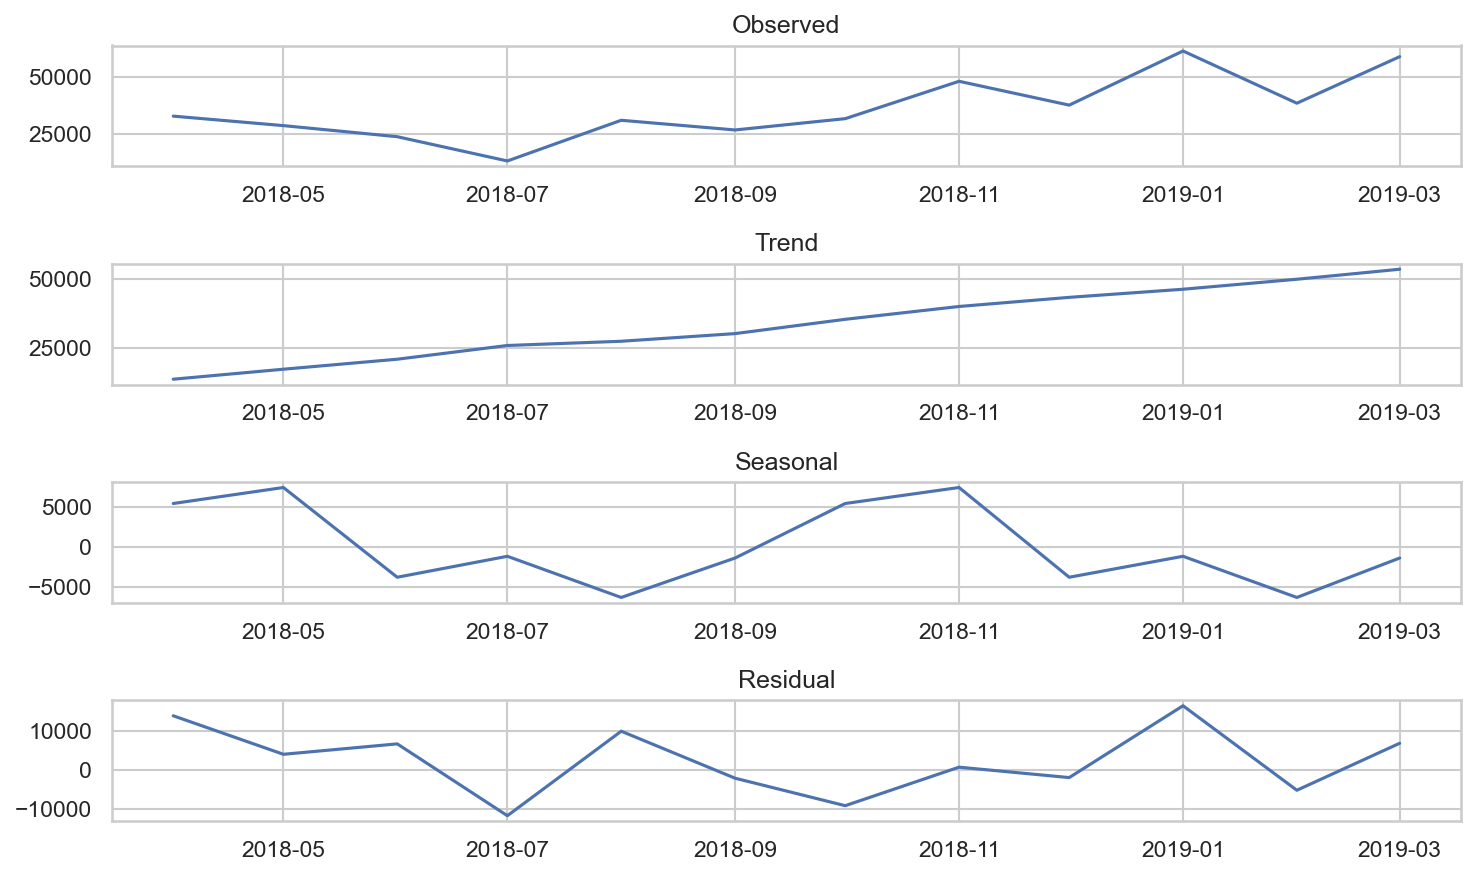

In [42]:

ts = monthly.set_index('ds')['total_sales'].asfreq('MS').fillna(0)

n_obs = len(ts)
if n_obs >= 24:
    period = 12
else:
    period = max(2, n_obs // 2)  

try:
    decomp = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
except Exception:
    from statsmodels.tsa.seasonal import STL
    from types import SimpleNamespace
    stl = STL(ts, period=period, robust=True)
    res = stl.fit()
    decomp = SimpleNamespace(observed=ts, trend=res.trend, seasonal=res.seasonal, resid=res.resid)

decomp.observed.to_frame('observed').join(
    decomp.trend.to_frame('trend')
).join(
    decomp.seasonal.to_frame('seasonal')
).join(
    decomp.resid.to_frame('resid')
).reset_index().to_csv(out_tb / "ts_decomposition_components.csv", index=False)

plt.figure(figsize=(10,6))
plt.subplot(411); plt.plot(decomp.observed); plt.title('Observed')
plt.subplot(412); plt.plot(decomp.trend); plt.title('Trend')
plt.subplot(413); plt.plot(decomp.seasonal); plt.title('Seasonal')
plt.subplot(414); plt.plot(decomp.resid); plt.title('Residual')
plt.tight_layout()
plt.savefig(out_ch / "time_series_decomposition.png", dpi=300)
plt.show()



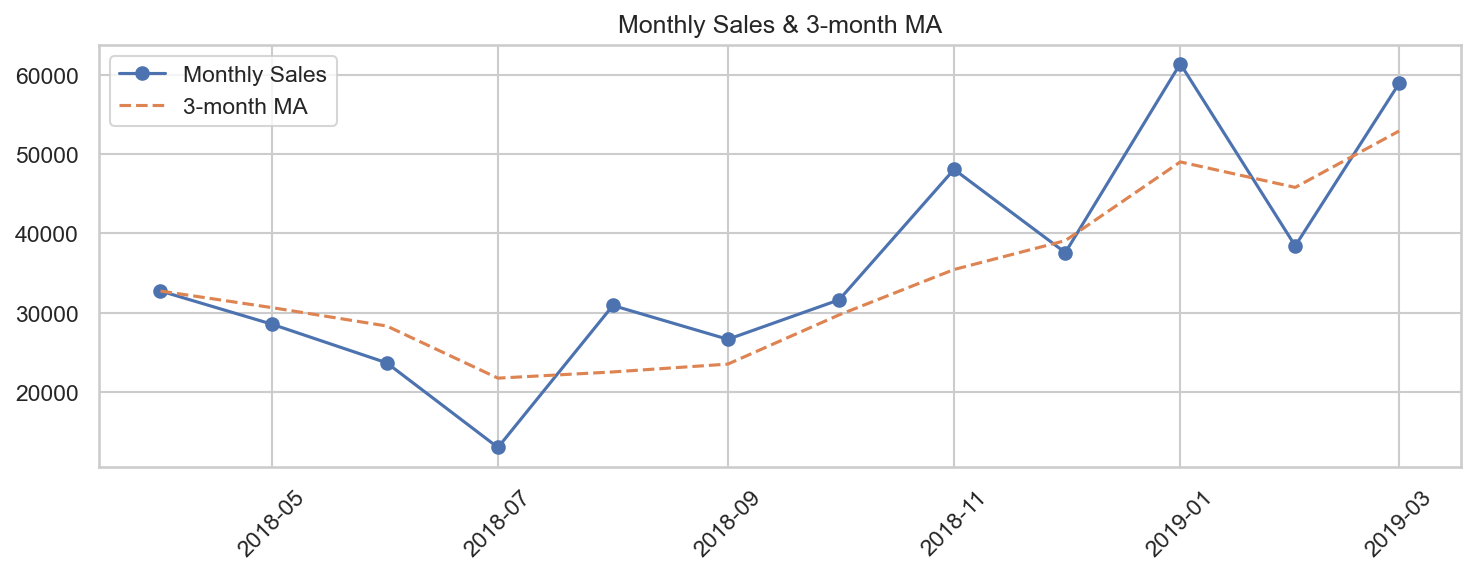

In [43]:
monthly['ma_3'] = monthly['total_sales'].rolling(3, min_periods=1).mean()
monthly[['ds','total_sales','ma_3']].to_csv(out_tb / "monthly_sales_moving_average.csv", index=False)
plt.figure(figsize=(10,4))
plt.plot(monthly['ds'], monthly['total_sales'], marker='o', label='Monthly Sales')
plt.plot(monthly['ds'], monthly['ma_3'], linestyle='--', label='3-month MA')
plt.xticks(rotation=45)
plt.legend()
plt.title("Monthly Sales & 3-month MA")
plt.tight_layout()
plt.savefig(out_ch / "monthly_sales_ma.png", dpi=300)
plt.show()


In [44]:
def simple_growth_forecast(series, periods):
    s = series.asfreq('MS').fillna(0)
    growth = s.pct_change().dropna()
    avg_growth = growth.tail(12).mean() if len(growth)>=1 else 0
    preds = []
    current = s.iloc[-1]
    idx = pd.date_range(start=s.index[-1] + pd.offsets.MonthBegin(1), periods=periods, freq='MS')
    for _ in range(periods):
        current = current * (1 + avg_growth)
        preds.append(current)
    return pd.DataFrame({'ds': idx, 'yhat': preds, 'yhat_lower': np.array(preds)*0.9, 'yhat_upper': np.array(preds)*1.1})


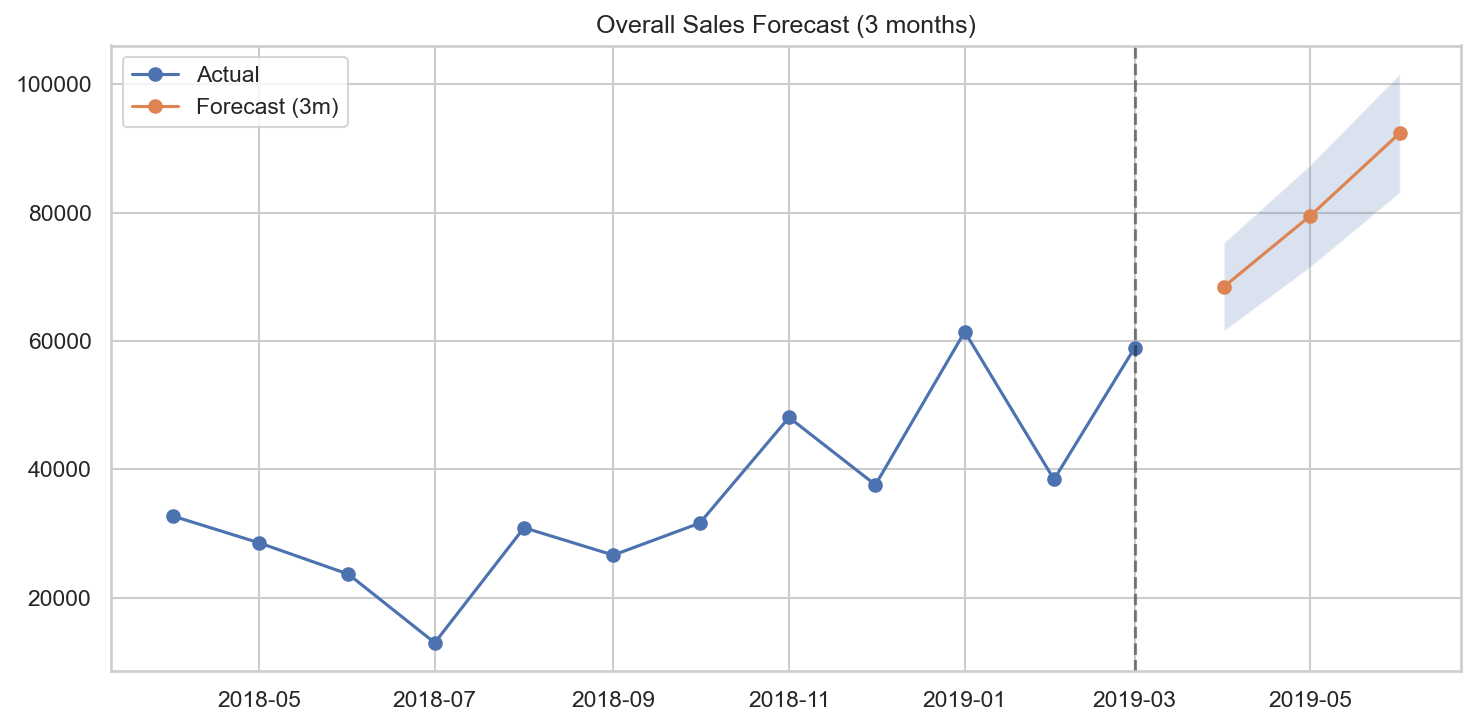

In [45]:

try:
    HORIZON
except NameError:
    HORIZON = 3

try:
    from prophet import Prophet
    PROPHET = True
except Exception:
    try:
        from fbprophet import Prophet
        PROPHET = True
    except Exception:
        PROPHET = False

if 'y' not in monthly.columns:
    monthly['y'] = monthly['total_sales']

if PROPHET:
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    m.fit(monthly[['ds', 'y']])
    future = m.make_future_dataframe(periods=HORIZON, freq='MS')
    fc = m.predict(future)[['ds','yhat','yhat_lower','yhat_upper']]
else:
    ts = monthly.set_index('ds')['y']
    fc = simple_growth_forecast(ts, HORIZON)
    hist = monthly[['ds','y']].rename(columns={'y':'actual'})
    fc = fc.reset_index(drop=True)

fc.to_csv(out_tb / "overall_sales_forecast_3m.csv", index=False)
plt.figure(figsize=(10,5))
plt.plot(monthly['ds'], monthly['y'], label='Actual', marker='o')
plt.plot(fc['ds'], fc['yhat'], label='Forecast (3m)', marker='o')
plt.fill_between(fc['ds'], fc['yhat_lower'], fc['yhat_upper'], alpha=0.2)
plt.axvline(monthly['ds'].max(), linestyle='--', color='k', alpha=0.5)
plt.legend()
plt.title("Overall Sales Forecast (3 months)")
plt.tight_layout()
plt.savefig(out_ch / "overall_sales_forecast_3m.png", dpi=300)
plt.show()


In [46]:

# ensure order_month exists (previous cell had this as markdown so might not have run)
if 'order_month' not in merged.columns:
    merged['order_month'] = pd.to_datetime(merged['order_date']).dt.to_period('M').astype(str)

cats = merged['category'].dropna().unique().tolist()
cat_forecasts = []
for cat in cats:
    df_cat = merged[merged['category'] == cat].groupby('order_month').agg(y=('amount', 'sum')).reset_index()
    df_cat['ds'] = pd.to_datetime(df_cat['order_month']).dt.to_period('M').dt.to_timestamp()
    df_cat = df_cat[['ds', 'y']].sort_values('ds').reset_index(drop=True)
    if len(df_cat) < 6:
        continue
    if PROPHET and len(df_cat) >= 12:
        m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        # Prophet expects columns ['ds', 'y']
        m.fit(df_cat[['ds', 'y']])
        future = m.make_future_dataframe(periods=HORIZON, freq='MS')
        fc_cat = m.predict(future)[['ds', 'yhat', 'yhat_lower', 'yhat_upper']]
    else:
        ts_cat = df_cat.set_index('ds')['y']
        fc_cat = simple_growth_forecast(ts_cat, HORIZON)
    fc_cat['category'] = cat
    cat_forecasts.append(fc_cat)

if cat_forecasts:
    cat_fc_df = pd.concat(cat_forecasts, ignore_index=True)
    cat_fc_df.to_csv(out_tb / "category_forecasts_3m.csv", index=False)


In [47]:

out_tb.joinpath("overall_sales_forecast_3m.csv")
out_tb.joinpath("category_forecasts_3m.csv")


PosixPath('/Users/saidattaputta/Desktop/Projects/Jar/outputs/tables/category_forecasts_3m.csv')